# Which Customers Carry the Profit? ABC Classification of 17,415 E-Commerce Customers

**Author:** Pham Hong Hieu (Haven) · **Data:** 51,290 order lines from a beauty and home-care e-commerce retailer,
2020–2023 (synthetic, educational)

## The question

A commercial team has limited account-management capacity and needs to know where to spend it. ABC analysis
ranks customers by the **profit** they generate and asks:

1. How concentrated is profit? Do a few customers carry most of it?
2. Who are the A, B and C customers, and do income or occupation set them apart?
3. What should the business do differently for each group, and for customers who lose money?

**Workflow:** load → check keys and clean → join → aggregate profit by customer → classify A/B/C at the 80% and 95%
cumulative thresholds → profile the groups → recommend.

## 1. Setup and data loading

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams.update({"axes.titleweight": "bold", "figure.dpi": 110})
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

DATA_DIR = Path("../data")
FIG_DIR = Path("../reports/figures")
TABLE_DIR = Path("../reports/tables")
GROUP_COLOURS = {"A": "#2E8B57", "B": "#E5A12B", "C": "#C8374D"}


def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

In [2]:
sales = pd.read_csv(DATA_DIR / "EcomSales.csv")
products = pd.read_csv(DATA_DIR / "Product.csv")
customers = pd.read_csv(DATA_DIR / "Customer.csv")
regions = pd.read_csv(DATA_DIR / "Region.csv")
for name, table in [("Sales", sales), ("Products", products), ("Customers", customers), ("Regions", regions)]:
    print(f"{name:<10} {table.shape[0]:>7,} rows x {table.shape[1]} columns")

Sales       51,290 rows x 11 columns
Products    28,356 rows x 4 columns
Customers   17,415 rows x 4 columns
Regions      3,828 rows x 4 columns


## 2. Data checks and cleaning

Before joining, check for nulls, duplicates and keys in the sales table that have no match in the reference
tables. An unmatched key would silently drop or misclassify sales.

In [3]:
checks = pd.DataFrame({
    "nulls": [t.isna().sum().sum() for t in (sales, products, customers, regions)],
    "duplicate_rows": [t.duplicated().sum() for t in (sales, products, customers, regions)],
}, index=["Sales", "Products", "Customers", "Regions"])
display(checks)

print("CustomerIDs in sales not in Customers:", (~sales["CustomerID"].isin(customers["CustomerID"])).sum())
print("ProductCodes in sales not in Products:", (~sales["ProductCode"].isin(products["ProductCode"])).sum())
print("RegionCodes in sales not in Regions:  ", (~sales["RegionCode"].isin(regions["RegionCode"])).sum())

,nulls,duplicate_rows
Sales,0,0
Products,0,0
Customers,124,0
Regions,0,0


CustomerIDs in sales not in Customers: 0
ProductCodes in sales not in Products: 2
RegionCodes in sales not in Regions:   2


In [4]:
# The unmatched codes are typing errors with a tripled prefix
display(sales.loc[~sales["ProductCode"].isin(products["ProductCode"]), ["OrderID", "ProductCode", "RegionCode"]])
display(sales.loc[~sales["RegionCode"].isin(regions["RegionCode"]), ["OrderID", "ProductCode", "RegionCode"]])

,OrderID,ProductCode,RegionCode
1,ID-2013-BD116051-41518,PPP000002,R0002
9,IN-2012-TH211151-41003,PPP000010,RRR0001


,OrderID,ProductCode,RegionCode
0,IN-2012-TH211151-41003,P000001,RRR0001
9,IN-2012-TH211151-41003,PPP000010,RRR0001


In [5]:
sales["ProductCode"] = sales["ProductCode"].replace({"PPP000002": "P000002", "PPP000010": "P000010"})
sales["RegionCode"] = sales["RegionCode"].replace({"RRR0001": "R0001"})
assert sales["ProductCode"].isin(products["ProductCode"]).all()
assert sales["RegionCode"].isin(regions["RegionCode"]).all()

# 124 customers have no gender recorded. Gender is not used in the ranking, so they are labelled
# "Unknown" rather than imputed, to avoid inventing information.
customers["Gender"] = customers["Gender"].fillna("Unknown")
print("Keys repaired; customers with unknown gender:", (customers["Gender"] == "Unknown").sum())

Keys repaired; customers with unknown gender:

 124


## 3. Profit by customer

Profit is summed over every order line of each customer. Customers whose total profit is **negative** cost the
business money overall. They cannot sit on a cumulative-share curve, so they are set aside as a separate group and
analysed in section 6.

In [6]:
customer_profit = (sales.groupby("CustomerID", as_index=False)["Profit"].sum()
                   .sort_values("Profit", ascending=False, ignore_index=True))
profitable = customer_profit[customer_profit["Profit"] >= 0].copy()
loss_making = customer_profit[customer_profit["Profit"] < 0].copy()

print(f"Customers: {len(customer_profit):,}")
print(f"  profit >= 0: {len(profitable):,}  (total ${profitable['Profit'].sum():,.0f})")
print(f"  profit <  0: {len(loss_making):,}  (total ${loss_making['Profit'].sum():,.0f})")
print(f"Net profit of all customers: ${customer_profit['Profit'].sum():,.0f}")

Customers: 17,415
  profit >= 0: 13,720  (total $1,332,433)
  profit <  0: 3,695  (total $-267,019)
Net profit of all customers: $1,065,414


## 4. ABC classification

Customers are ranked by profit, and each customer's cumulative share of total profit decides the group:

| Group | Cumulative profit share |
|---|---|
| A | first 80% |
| B | next 15% (80–95%) |
| C | last 5% |

In [7]:
profitable["cum_pct"] = profitable["Profit"].cumsum() / profitable["Profit"].sum() * 100
profitable["ABC"] = np.select(
    [profitable["cum_pct"] <= 80, profitable["cum_pct"] <= 95],
    ["A", "B"],
    default="C",
)

abc = (profitable.groupby("ABC")
       .agg(customers=("CustomerID", "count"), profit=("Profit", "sum"), avg_profit=("Profit", "mean"))
       .reset_index())
abc["customer_pct"] = abc["customers"] / abc["customers"].sum() * 100
abc["profit_pct"] = abc["profit"] / abc["profit"].sum() * 100
abc.to_csv(TABLE_DIR / "abc_summary.csv", index=False)
abc

,ABC,customers,profit,avg_profit,customer_pct,profit_pct
0,A,4031,"1,065,940.74",264.44,29.38,80.00
1,B,3752,"199,869.39",53.27,27.35,15.00
2,C,5937,"66,622.59",11.22,43.27,5.00


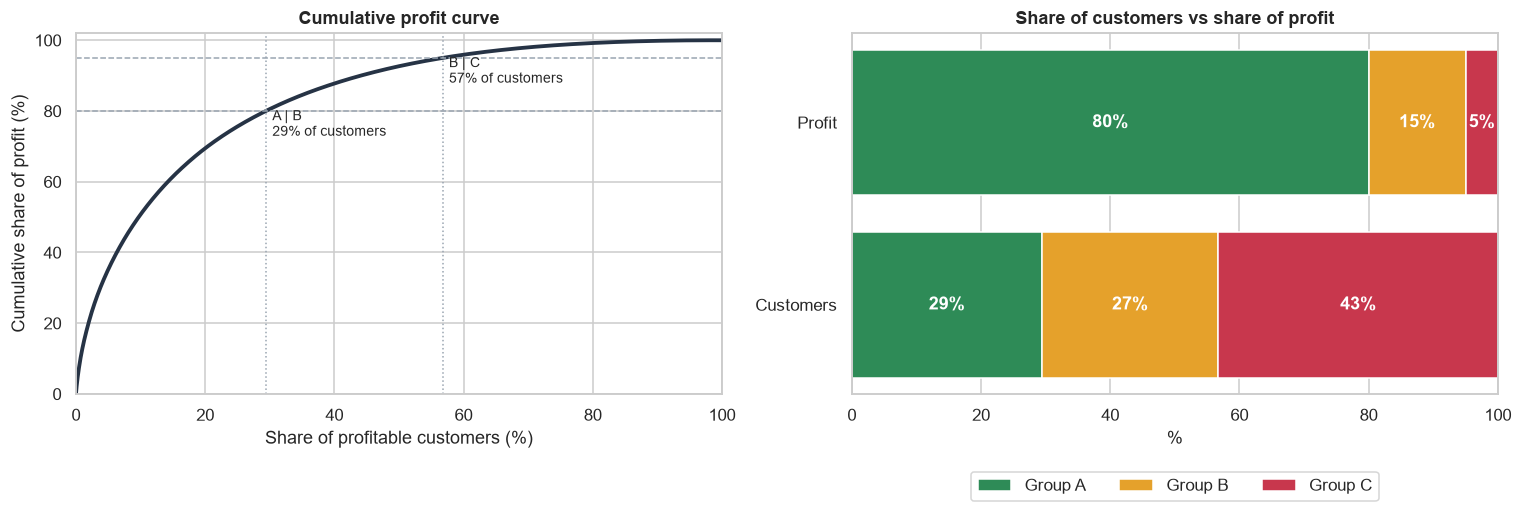

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ranked = profitable.reset_index(drop=True)
x = (ranked.index + 1) / len(ranked) * 100
axes[0].plot(x, ranked["cum_pct"], color="#263345", linewidth=2.5)
for threshold, label in [(80, "A | B"), (95, "B | C")]:
    cut = x[np.argmax(ranked["cum_pct"].to_numpy() > threshold)]
    axes[0].axhline(threshold, color="#9AA5B1", linestyle="--", linewidth=1)
    axes[0].axvline(cut, color="#9AA5B1", linestyle=":", linewidth=1)
    axes[0].text(cut + 1, threshold - 7, f"{label}\n{cut:.0f}% of customers", fontsize=9)
axes[0].set(title="Cumulative profit curve", xlabel="Share of profitable customers (%)",
            ylabel="Cumulative share of profit (%)", xlim=(0, 100), ylim=(0, 102))

share = abc.set_index("ABC")[["customer_pct", "profit_pct"]].T
share.index = ["Customers", "Profit"]
left = np.zeros(2)
for group in ["A", "B", "C"]:
    axes[1].barh(share.index, share[group], left=left, color=GROUP_COLOURS[group], label=f"Group {group}")
    for i, value in enumerate(share[group]):
        axes[1].text(left[i] + value / 2, i, f"{value:.0f}%", ha="center", va="center", color="white", fontweight="bold")
    left += share[group].to_numpy()
axes[1].set(title="Share of customers vs share of profit", xlabel="%", xlim=(0, 100))
axes[1].legend(loc="lower center", bbox_to_anchor=(0.5, -0.32), ncol=3)
fig.tight_layout()
save(fig, "01_abc_concentration")
plt.show()

Profit is concentrated, but less than the 80/20 rule suggests. About **29%** of profitable customers (group A) earn
80% of the profit, while the 43% in group C together contribute only 5%.

## 5. Who are the A, B and C customers?

A useful segmentation should describe customers in a way the business can act on. Income and occupation are
the two demographic fields available.

,mean,median
ABC,,
A,"56,366.00","60,000.00"
B,"57,079.00","60,000.00"
C,"58,023.00","60,000.00"


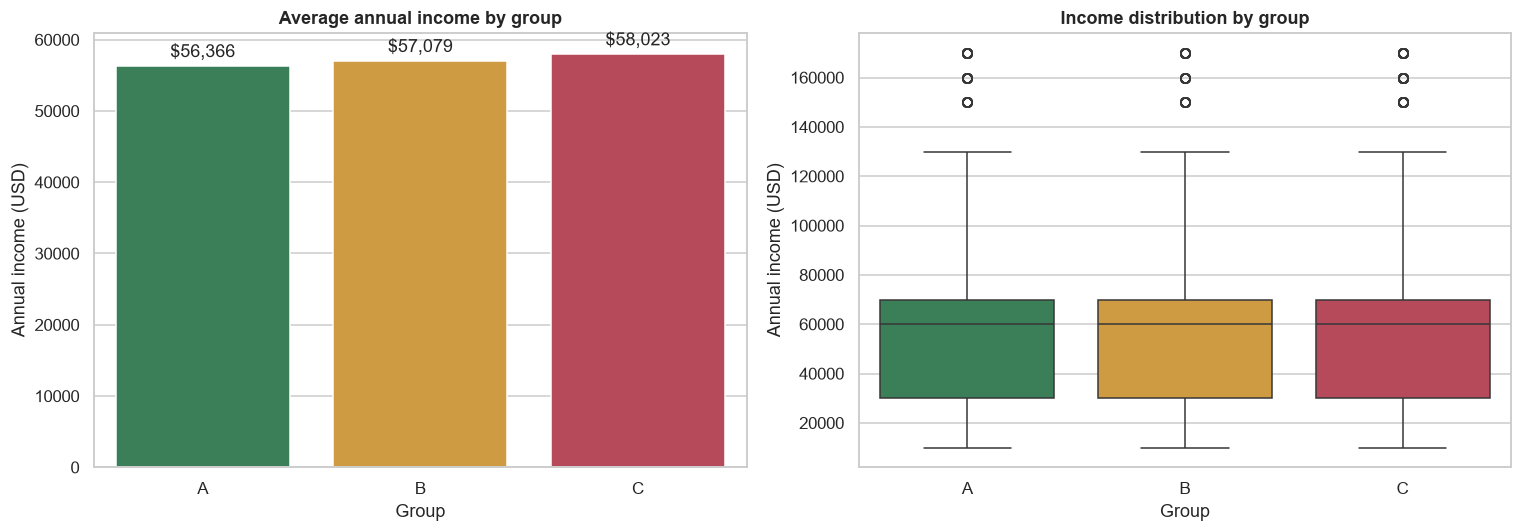

In [9]:
profile = profitable.merge(customers[["CustomerID", "AnnualIncome", "Occupation", "Gender"]],
                           on="CustomerID", how="left", validate="one_to_one")

income = profile.groupby("ABC")["AnnualIncome"].agg(["mean", "median"]).round(0)
display(income)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(data=profile, x="ABC", y="AnnualIncome", order=["A", "B", "C"], hue="ABC",
            palette=GROUP_COLOURS, legend=False, errorbar=None, ax=axes[0])
for container in axes[0].containers:
    axes[0].bar_label(container, fmt="${:,.0f}", padding=3)
axes[0].set(title="Average annual income by group", xlabel="Group", ylabel="Annual income (USD)")
sns.boxplot(data=profile, x="ABC", y="AnnualIncome", order=["A", "B", "C"], hue="ABC",
            palette=GROUP_COLOURS, legend=False, ax=axes[1])
axes[1].set(title="Income distribution by group", xlabel="Group", ylabel="Annual income (USD)")
fig.tight_layout()
save(fig, "02_income_by_group")
plt.show()

ABC,A,B,C
Occupation,,,
Professional,28.80,28.90,30.10
Skilled Manual,25.70,25.80,24.90
Clerical,16.10,15.80,15.10
Management,15.60,16.00,17.20
Manual,13.80,13.60,12.70


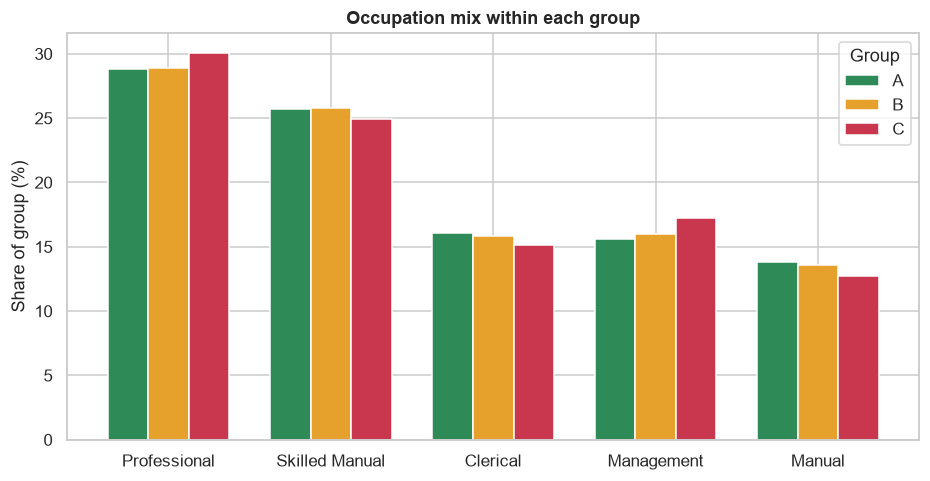

In [10]:
occupation_mix = (pd.crosstab(profile["Occupation"], profile["ABC"], normalize="columns") * 100).round(1)
occupation_mix = occupation_mix.loc[occupation_mix["A"].sort_values(ascending=False).index]
display(occupation_mix)

fig, ax = plt.subplots(figsize=(10, 4.8))
occupation_mix[["A", "B", "C"]].plot(kind="bar", color=[GROUP_COLOURS[g] for g in "ABC"], ax=ax, width=0.75)
ax.set(title="Occupation mix within each group", xlabel="", ylabel="Share of group (%)")
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Group")
save(fig, "03_occupation_mix")
plt.show()

Average income is almost the same in all three groups, between about $56K and $58K, and the occupation mix is nearly
identical across groups. **Demographics do not explain who becomes an A customer.** Value is driven by purchasing
behaviour: how often a customer orders, what they buy and at what discount. It does not follow from who they are.
Targeting high-value customers by income or job title would not work in this business.

## 6. The fourth group: customers who lose money

In [11]:
loss_lines = sales[sales["CustomerID"].isin(loss_making["CustomerID"])]
deep_discount = (loss_lines["Discount"] > 0.2).mean() * 100
all_deep = (sales["Discount"] > 0.2).mean() * 100

print(f"Loss-making customers: {len(loss_making):,} ({len(loss_making) / len(customer_profit):.1%} of all customers)")
print(f"Profit they destroy:  ${-loss_making['Profit'].sum():,.0f}")
print(f"That equals {-loss_making['Profit'].sum() / profitable['Profit'].sum():.1%} of the profit earned by groups A-C")
print(f"Share of their order lines discounted above 20%: {deep_discount:.0f}% (all customers: {all_deep:.0f}%)")

loss_making.sort_values("Profit").head(10)  # the ten largest losses

Loss-making customers: 3,695 (21.2% of all customers)
Profit they destroy:  $267,019
That equals 20.0% of the profit earned by groups A-C
Share of their order lines discounted above 20%: 78% (all customers: 22%)


,CustomerID,Profit
17414,RR-9525134,"-2,154.80"
17413,AH-690147,"-1,989.40"
17412,AJ-78095,"-1,714.20"
17411,PC-1874588,"-1,642.48"
17410,KB-658568,"-1,528.80"
17409,CB-253595,"-1,503.60"
17408,MK-7905134,"-1,492.70"
17407,EB-1370559,"-1,350.48"
17406,KB-660095,"-1,317.45"
17405,MY-8295134,"-1,221.00"


About one customer in five (21%) has negative lifetime profit, and together these customers destroy about
**$267K**. That equals **20%** of all the profit that groups A to C generate. The driver is discounting. 78% of their
order lines carry a discount above 20%, against 22% across all customers. This group is invisible in a standard
ABC chart, yet it is probably the quickest place to recover profit.

## 7. Recommendations

| Group | Profile | Action |
|---|---|---|
| **A** (29% of profitable customers, 80% of profit) | Highest lifetime profit; not distinguishable by income or occupation | Dedicated account management, early access and loyalty rewards; monitor churn signals monthly |
| **B** (27%, 15%) | Solid contributors | Cross-sell and volume incentives to move them toward A |
| **C** (43%, 5%) | Low profit per customer | Serve through low-cost, automated channels; avoid costly retention offers |
| **Loss-making** (21% of all customers) | Negative lifetime profit, heavy discounting | Review discount eligibility and minimum order values before acquiring more of this profile |

## 8. Limitations

- The data are synthetic and educational, so the findings illustrate the method rather than describe a real business.
- ABC is based on lifetime profit, so it does not separate long-standing customers from recent ones. Combining it
  with recency (RFM) would show which A customers are still active.
- Only income, occupation and gender are available. Behavioural variables would be needed to predict group
  membership.